*Notebook 09 of 12 in `notebooks/scripts_text/`. Parameters: `analysis/scripts_text/config.yaml`; decisions and run notes: `analysis/scripts_text/LOG.md`. The static page `site/scripts/index.html` is built from the same outputs.*

In [1]:
import sys
from pathlib import Path

REPO = Path.cwd().resolve().parents[1]   # notebooks/scripts_text -> repo root
sys.path.insert(0, str(REPO))

import warnings

import pandas as pd
import plotly.io as pio
from IPython.display import Markdown, display

from analysis.scripts_text.report import nb_md
from analysis.static_figures import use_static_figures

from analysis.scripts_text import s09_logreg as step

use_static_figures()   # figures become static PNGs (they show on GitHub); interactive ones are on the static page
warnings.filterwarnings("ignore", category=RuntimeWarning)   # known 0/0 on very short arcs, handled downstream
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

## Step 9 · A second method: logistic regression on TF-IDF

This step asks whether a model that uses all the words at once can tell successful from unsuccessful scripts
better than genre, decade and budget alone.

### What we do

We turn each script's dialogue into a TF-IDF vector, a set of word weights that are high for words the script
uses often and few other scripts use. We follow the course definitions: tf = count / |d| (the word's count
divided by the script's length) and idf = ln(N / df) (N scripts, df the number of scripts using the word),
computed on the training scripts only so the test scripts stay unseen. A logistic regression then predicts the
success label of definition (C) from that vector. We use cross-validation, which fits the model on part of the
scripts and tests it on the rest, rotating the held-out part. It's 5-fold, repeated 10 times, with folds
balanced on label × primary genre. We compare the model with a **baseline** that only knows genre, decade and
log budget, and with the text model trained on shuffled labels.

### Why

Scattertext looks at one word at a time. A classifier uses all the words together and is scored on scripts it
hasn't seen, so it answers a different question: is there *any* reliable signal in the dialogue? Agreement
between the two methods is evidence, and disagreement is a warning.

### What it measures

AUC, the chance that a randomly chosen successful script gets a higher score than a randomly chosen
unsuccessful one. 0.5 is a coin flip and 1 is perfect.

### How to read a coefficient

A positive coefficient means that, holding the other words fixed, more of this word goes with a higher
predicted chance of being in the successful group, in this corpus. It's an association, not a cause, and with
thousands of correlated words a single coefficient is unstable.

### What it misses

A linear model on word frequencies ignores order, meaning and context. We don't use scikit-learn's
`TfidfVectorizer`, because its idf adds 1 even without smoothing. We compute the course formula directly
instead.

> **Takeaway.** A classifier that reads the dialogue reaches a mean AUC of 0.584, against 0.576 for genre, decade and budget alone (0.5 = chance). Text and baseline aren't clearly different.

In [2]:
res = step.run()   # recomputes this step and saves its outputs

**Figure.** Cross-validated AUC for each test fold: the baseline (genre, decade, budget), text only, both together, and the text model trained on shuffled labels. The dashed line is chance.

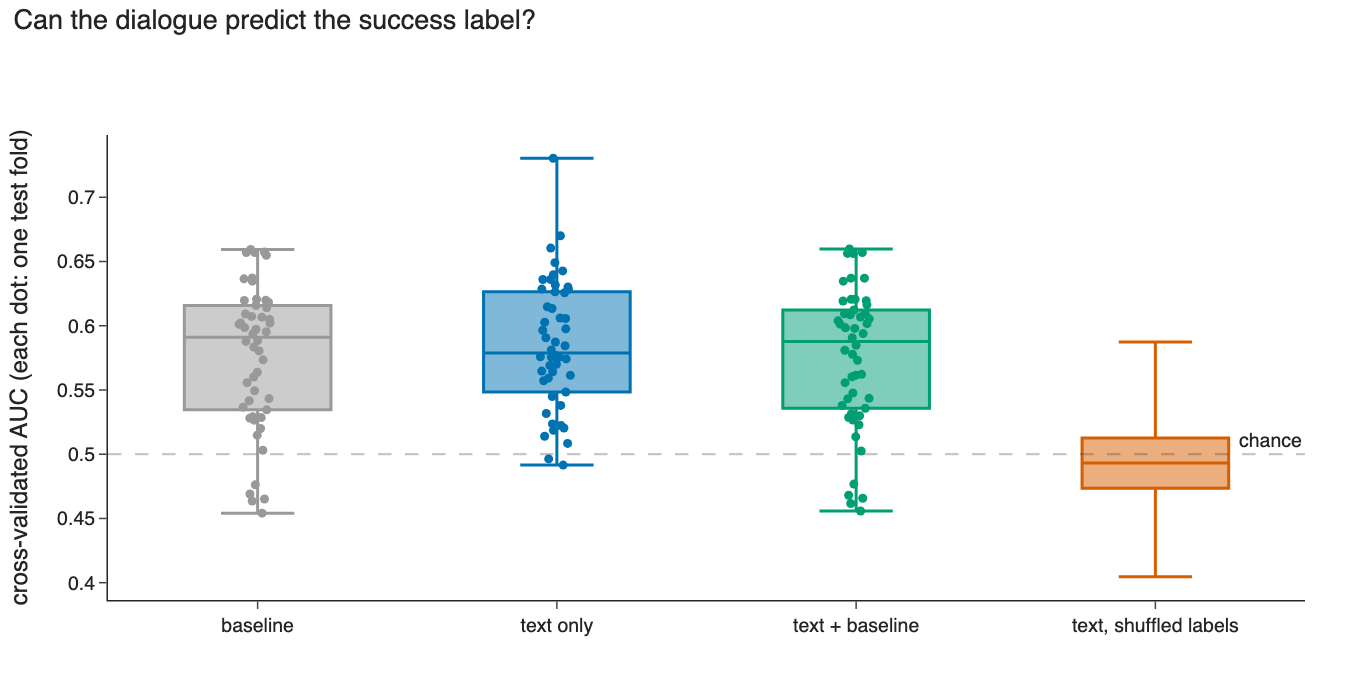

In [3]:
step.figures(res)["auc"].show()

**Table.** Mean AUC, with the spread over folds and over the 10 repeats.

In [4]:
display(step.tables(res)["auc"])

,model,mean AUC,95% of folds within,range of the 10 repeat means
0,TF-IDF text only,0.584,0.50–0.67,0.557–0.612
1,baseline: genre + decade + log budget,0.576,0.46–0.66,0.559–0.587
2,text + baseline,0.574,0.46–0.66,0.560–0.586
3,"text only, labels shuffled (null)",0.491,sd 0.032 over 200 shuffles,–


**Table.** The 20 most positive and most negative coefficients of the text model fitted on all scripts. They're associations in this corpus only.

In [5]:
display(step.tables(res)["coefficients"])

,positive (successful),coefficient,negative (unsuccessful),coefficient
0,yah,0.39,sparky,-0.39
1,rocky,0.38,jerry,-0.25
2,je,0.30,yer,-0.23
3,pas,0.30,jake,-0.22
4,hee,0.29,ye,-0.21
5,master,0.29,gem,-0.19
6,balboa,0.26,piper,-0.17
7,ya,0.25,padre,-0.16
8,parker,0.22,judges,-0.16
9,c'est,0.22,jimmy,-0.16


**Plain-language reading** (generated from the saved numbers):

In [6]:
display(Markdown(nb_md(step.reading(res))))

On 526 scripts (290 successful), 10 repeats of 5-fold cross-validation give a mean AUC of 0.584 for the TF-IDF text model, 0.576 for the genre + decade + budget baseline and 0.574 for both together (0.5 = chance). With labels shuffled within genre × decade cells, the text model averages 0.491 (sd 0.032, 200 shuffles), so the real text AUC has an empirical p = 0.010. Text and baseline are **not clearly different**, because the means of the 10 repeats overlap (0.557 to 0.612 for text, 0.559 to 0.587 for the baseline). Fold by fold, the text model is ahead in 52% of test folds. Its top-50 positive coefficients overlap the Scattertext top 50 with a Jaccard of 0.52 (0.49 on the negative side).